# 🧪 LAB: Implement an autoencoder with `PyTorch`

In this lab, you will implement and explore autoencoders using the MNIST dataset. The goal is to understand how autoencoders learn compressed representations of data, and how these representations compare with classical methods like PCA.

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


NAME(s) = ""

## 1. Theoretical Background Reflection (10 points)

Read *Michelucci (2022)*: [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898) — focus on the following sections:  
- 1. Introduction
- 2.1, 2.2, and 2.3
- Skim Section 3 on applications  

Then answer briefly:

1. What is the main idea behind an autoencoder?  
2. What is the role of the bottleneck layer?  
3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  
4. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?


1. The main idea of an autoencoder is the reconstruct an input with the lowest number of errors possible in the resulting output. Ultimately, the goal of an autoencoder is to learn an informative representation of the data that is being inputted, so it can be used for different applications.

2. The Bottleneck layer in an Feed-Forward Autoencoder decreases the amount of neurons in comparison to the input layer. Bottleneck layers can be any layer that lowers the number of neurons in the autoencoder, including the feature generating layer in the middle of the autoencoder.

3. The main application of autoencoders is to perform anomaly detection, which is when images that are foreign to a dataset of known images are inputted into the autoencoder. Since the system is unfamiliar with the image, it will have a hard time reconstructing the image, thus making the final output look much different, due to a high reconstruction error

4. PCA is linear, which makes it very good at handling smaller data that does not deal with many non-linear relationships. Autoencoders, on the other hand, works with data in small batches, making it better at handling large pools of data than involve non-linear transformations and relationships.

## 2. Prepare the Data (10 points)

Given the below dataset:

- Normalize **each** image (i.e., separately) so its values are between 0 and 1. Remember our first-week discussions of fixed and fitted transformations.
- Visualize a few random digits to confirm everything worked as expected.
- Split the dataset into fitting, tuning and reporting sets (70%, 15%, 15%).
- Wrap each data splitting as `DataLoader` object with a batch size of 128. Call them `fitting_loader`, `tuning_loader` and `reporting_loader`, respectively.

In [ ]:
import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

In [ ]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

: 

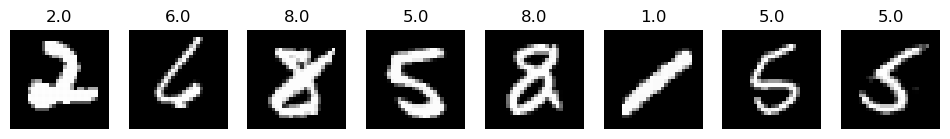

In [ ]:
# USE AS MANY CELLS AS NEEDED
import numpy as np
from torch.utils.data import DataLoader

# normalize the features and target variable
X = X.astype(np.float32)
X_min = X.min(axis=1, keepdims=True)
X_max = X.max(axis=1, keepdims=True)
X_norm = (X - X_min) / np.maximum(X_max - X_min, 1e-8)

y = y.astype(np.float32)
y_min = y.min()
y_max = y.max()
y_norm = (y - y_min) / np.maximum(y_max - y_min, 1e-8)


# visualize the scaled features and target variable
import matplotlib.pyplot as plt

idx = np.random.choice(len(X_norm), 8, replace=False)
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, idx):
    ax.imshow(X_norm[i].reshape(28, 28), cmap="gray")
    ax.set_title(y[i]); ax.axis("off")
plt.show()

# split the data into training and testing sets and report
from sklearn.model_selection import train_test_split

X_fit, X_hold, y_fit, y_hold = train_test_split(X_norm, y_norm, test_size=0.15, random_state=42)
X_fit, X_report, y_fit, y_report = train_test_split(X_fit, y_fit, test_size=0.176, random_state=42)

print(f"Training set: {X_fit.shape[0]} samples")
print(f"Validation set: {X_hold.shape[0]} samples")
print(f"Testing set: {X_report.shape[0]} samples")
print(f"Training labels: {y_fit.shape[0]} samples")
print(f"Validation labels: {y_hold.shape[0]} samples")
print(f"Testing labels: {y_report.shape[0]} samples")

# dataloader
from torch.utils.data import TensorDataset
import torch
fit_dataset = TensorDataset(torch.tensor(X_fit), torch.tensor(y_fit))
hold_dataset = TensorDataset(torch.tensor(X_hold), torch.tensor(y_hold))
report_dataset = TensorDataset(torch.tensor(X_report), torch.tensor(y_report))
fitting_loader = DataLoader(fit_dataset, batch_size=128, shuffle=True)
tuning_loader = DataLoader(report_dataset, batch_size=128, shuffle=False)
reporting_loader = DataLoader(hold_dataset, batch_size=128, shuffle=False)





## 3. Autoencoder

In this section, you will build and train an **autoencoder** to reconstruct the provided data.

Your model will include three layers in both the encoder and decoder:

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Implementation (30 points)

Follow the skeleton provided below and fill in the missing parts (`#TODO`). 

Follow these restrictions:

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. Determine the appropriate order for these components based on what we discussed in class. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [ ]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # TODO: Add steps to go from 784 to 128 
            # TODO: Add steps to go from 128 to 64 
            # TODO: Add steps to go from 64 to 2. 
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'encoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.encoder_list = None
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # TODO: Add steps to go from 2 to 64
            # TODO: Add steps to go from 64 to 128  
            # TODO: Add steps to go from 128 to 784. 
        ]
        # TODO: Replace the None value below with the module that stores the layers in 'decoder_list' for manual iteration in the forward pass
        # Hint: we have covered this module in class
        self.decoder_list = None
        
    def forward(self, X):
        # TODO: Replace the None value below for that after applying X -> encoder -> decoder
        # Hint: You will probably need to iterate through the encoder_list and decoder_list
        output = None
        return output


### 3.2 Training (15 points)

Follow the skeleton provided below and fill in the missing parts to train your model (`#TODO`). As you can see, training includes EarlyStopping, which I give you already for your convenience :-). After you have filled these missing parts, uncomment the provided piece of code with the function for training (`train_autoencoder`) your model and execute it.

But, **BEFORE** that, discuss with your mates and provide elaborated answers to the following:

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?
- Based on this, which cost function is most appropriate for this task? Justify your choice.

YOUR RESPONSES HERE. YOU MAY USE MORE CELLS THAN THIS ONE

Once you have discussed and agreed on the reasoning above, proceed to complete the skeleton (`#TODO`) and train the model.


In [ ]:
# TODO: Replace None to instantiate the autoencoder
model = None  

# TODO: Replace None with the appropriate Loss function from 'torch.nn'
# Hint: we are reconstructing continuous pixel values in [0,1]
criterion = None  

# TODO: Replace None with Adam optimizer. 
# Use learning rate of 0.001 and an L2 regularization via weight_decay of 1e-5
optimizer = None  

In [ ]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            # --- Implement the standard training steps ---
            
            outputs = None  # TODO: Forward pass for this batch
            cost = None     # TODO: Compute the cost for this batch
            # TODO: Backward pass (compute gradients)
            # TODO: Update model parameters
            # TODO: Set gradients equal to zero
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = None  # TODO: Forward pass for tuning data
                cost = None     # TODO: Compute the tuning cost
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Once the missing parts have been filled, uncomment the piece of code below and execute it to train your model (it may take a bit to complete the training, which is totally normal).

In [ ]:
# model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

In [ ]:
# USE AS MANY CELLS AS NEEDED FOR THE REST OF THE CODE

### 3.3 Reconstruct (5 points)

Once you have trained the model: 

1. Visualize several reconstructed digits from the reporting set.  
2. Compare them with the corresponding original input digits. Was the reconstruction good? 

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 4. Visualize the Learned Representations (15 points)

Here you will explore the latent representations learned by your autoencoder.

1. Complete `extract_latent_features` to extract the latent (bottleneck) features and their corresponding labels, given a trained model.  
   Apply this function to the reporting set using the provided code. This should give you the transformed reporting set with the dimensions of the bottleneck (2).
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [ ]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            encoded = None  # TODO: Apply the encoder part of the model to get the latent features
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels

Once the missing parts above have been filled, uncomment the piece of code below and execute it to extract the latent features

In [ ]:
# latents_autoencoder, labels = extract_latent_features(model, reporting_loader)

In [ ]:
# USE AS MANY CELLS AS NEEDED FOR THE REST OF THE CODE

## 5. Compare with PCA (10 points)

Here you will compare the latent representations learned by your autoencoder with those obtained using a PCA.

1. Apply a PCA to the reporting set (without using the autoencoder) to reduce the data to the same dimensionality as your bottleneck (2 dimensions). Obviously, first use the rest of the data to learn these two components.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA) and briefly discuss the differences (if any) you observe.

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE